# Assignment 10

## Task - 1: Data Loading and Preprocessing
1. Load the [UCI Seeds dataset](https://archive.ics.uci.edu/dataset/236/seeds).
2. Check for missing values and duplicate rows in the dataset.
3. Handle any missing or duplicate data appropriately.

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, rand_score, adjusted_rand_score,
    accuracy_score, precision_score, recall_score,
)

sns.set_theme(style="whitegrid")

In [2]:
# Load the seven measurements and the ground truth class from UCI
feature_names = [
    "Area", "Perimeter", "Compactness", "Kernel length",
    "Kernel width", "Asymmetry coefficient", "Groove length",
]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"
df = pd.read_csv(url, sep=r"\s+", header=None, names=feature_names + ["Class"])

print("Dataset: UCI Seeds (210 samples, 7 measurements, 3 wheat classes)")
assert df.shape == (210, 8)
print("Dataset shape before cleaning:", df.shape)
display(df.head())
print("Missing values per column:")
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset: UCI Seeds (210 samples, 7 measurements, 3 wheat classes)
Dataset shape before cleaning: (210, 8)


,Area,Perimeter,Compactness,Kernel length,Kernel width,Asymmetry coefficient,Groove length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Missing values per column:
Area                     0
Perimeter                0
Compactness              0
Kernel length            0
Kernel width             0
Asymmetry coefficient    0
Groove length            0
Class                    0
dtype: int64
Duplicate rows: 0


In [3]:
# Remove rows without ground truth and duplicates; impute missing measurements
df = df.dropna(subset=["Class"]).drop_duplicates().reset_index(drop=True)
df[feature_names] = df[feature_names].fillna(df[feature_names].median())
df["Class"] = df["Class"].astype(int)
print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isna().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())
print("Class counts (1: Kama, 2: Rosa, 3: Canadian):")
print(df["Class"].value_counts().sort_index())

Dataset shape after cleaning: (210, 8)
Remaining missing values: 0
Remaining duplicate rows: 0
Class counts (1: Kama, 2: Rosa, 3: Canadian):
Class
1    70
2    70
3    70
Name: count, dtype: int64


In [4]:
# Standardize measurements so large-scale features do not dominate distances
scaler = StandardScaler()
X = scaler.fit_transform(df[feature_names])
y = df["Class"].to_numpy()
assert np.isfinite(X).all() and len(X) == len(y)

## Task - 2: K-Means Clustering Implementation from Scratch

1. Implement the K-Means algorithm from scratch.
2. Use K-Means++ initialization to select initial centroids.
3. Perform clustering with 3 clusters.
4. Display the final cluster centroids and the number of samples in each cluster.

In [5]:
def kmeans_plus_plus(data, clusters, rng):
    """Select centers with probability proportional to squared distance."""
    centroids = np.empty((clusters, data.shape[1]))
    centroids[0] = data[rng.integers(len(data))]
    closest_squared = np.sum((data - centroids[0]) ** 2, axis=1)

    for j in range(1, clusters):
        probabilities = closest_squared / closest_squared.sum()
        centroids[j] = data[rng.choice(len(data), p=probabilities)]
        squared_distances = np.sum((data - centroids[j]) ** 2, axis=1)
        closest_squared = np.minimum(closest_squared, squared_distances)
    return centroids


def assign_clusters(data, centroids):
    """Assign each sample to its nearest centroid."""
    squared_distances = np.sum((data[:, None, :] - centroids[None, :, :]) ** 2, axis=2)
    return np.argmin(squared_distances, axis=1)


def KMeans_from_scratch(input, clusters=3, tolerance=1e-4,
                        max_iterations=300, random_state=42):
    """Run K-Means with K-Means++ initialization and Euclidean distance."""
    data = np.asarray(input, dtype=float)
    if data.ndim != 2 or 0 in data.shape or not np.isfinite(data).all():
        raise ValueError("Input must be a nonempty, finite 2D array.")
    if not isinstance(clusters, (int, np.integer)) or not 1 <= clusters <= len(np.unique(data, axis=0)):
        raise ValueError("Cluster count must be between 1 and the number of distinct samples.")
    if tolerance < 0 or max_iterations < 1:
        raise ValueError("Tolerance must be nonnegative and max_iterations must be positive.")

    rng = np.random.default_rng(random_state)
    centroids = kmeans_plus_plus(data, clusters, rng)

    for _ in range(max_iterations):
        labels = assign_clusters(data, centroids)
        new_centroids = np.empty_like(centroids)
        closest_squared = np.sum((data - centroids[labels]) ** 2, axis=1)

        for j in range(clusters):
            members = data[labels == j]
            if len(members):
                new_centroids[j] = members.mean(axis=0)
            else:
                # Restart an empty cluster at a poorly represented sample
                farthest = np.argmax(closest_squared)
                new_centroids[j] = data[farthest]
                closest_squared[farthest] = -np.inf

        shift = np.linalg.norm(new_centroids - centroids)
        centroids = new_centroids
        if shift <= tolerance:
            break

    return centroids, assign_clusters(data, centroids)

In [6]:
# Cluster all 210 UCI Seeds samples using the seven standardized measurements
scratch_centroids, scratch_labels = KMeans_from_scratch(X, clusters=3)

# Verify the results on the provided dataset
assert X.shape == (210, 7) and scratch_centroids.shape == (3, 7)
assert np.array_equal(np.unique(scratch_labels), [0, 1, 2])
for cluster in range(3):
    assert np.allclose(scratch_centroids[cluster], X[scratch_labels == cluster].mean(axis=0))

print("Final centroids (standardized features):")
display(pd.DataFrame(scratch_centroids, columns=feature_names).rename_axis("Cluster").round(4))
print("Final centroids (original measurement scale):")
scratch_centroids_original = scaler.inverse_transform(scratch_centroids)
display(pd.DataFrame(scratch_centroids_original, columns=feature_names).rename_axis("Cluster").round(4))
print("Number of samples in each cluster:")
display(pd.Series(scratch_labels, name="Cluster").value_counts().sort_index().rename("Samples").to_frame())

Final centroids (standardized features):


,Area,Perimeter,Compactness,Kernel length,Kernel width,Asymmetry coefficient,Groove length
Cluster,,,,,,,
0,-0.2200,-0.2554,0.4179,-0.3533,-0.0629,-0.6538,-0.6768
1,1.2168,1.2257,0.5354,1.2108,1.1236,-0.0626,1.2656
2,-1.0439,-1.0135,-1.0364,-0.8881,-1.1211,0.7995,-0.5835


Final centroids (original measurement scale):


,Area,Perimeter,Compactness,Kernel length,Kernel width,Asymmetry coefficient,Groove length
Cluster,,,,,,,
0,14.2089,14.2265,0.8808,5.4724,3.2349,2.7195,5.0762
1,18.3797,16.1561,0.8836,6.1637,3.6820,3.6063,6.0286
2,11.8173,13.2388,0.8466,5.2360,2.8362,4.8994,5.1220


Number of samples in each cluster:


,Samples
Cluster,
0,74
1,70
2,66


## Task - 3: Cluster Evaluation

1. Evaluate the silhouette and Rand scores using scikit-learn functions.


In [7]:
scratch_silhouette = silhouette_score(X, scratch_labels)
scratch_rand = rand_score(y, scratch_labels)

print(f"Silhouette Score (from scratch): {scratch_silhouette:.4f}")
print(f"Rand Index (from scratch):       {scratch_rand:.4f}")

Silhouette Score (from scratch): 0.4039
Rand Index (from scratch):       0.9049


## Task - 4: Ground Truth Comparison and Label Assignment

1. Using the ground truth labels available in the dataset, create a table showing how many samples of each true class fall into each cluster.
2. For each cluster, assign the majority class label to that cluster.
3. Compute accuracy, precision, and recall based on this assignment.

In [8]:
def majority_class_evaluation(labels_true, cluster_labels):
    """Map each cluster to its majority true class, then evaluate the mapping."""
    table = pd.crosstab(
        pd.Series(labels_true, name="True class"),
        pd.Series(cluster_labels, name="Cluster"),
    )
    # idxmax chooses the smallest class label in a tie because rows are sorted
    majority_labels = table.idxmax(axis=0)
    assigned_labels = np.array([majority_labels[label] for label in cluster_labels])
    metrics = {
        "Accuracy": accuracy_score(labels_true, assigned_labels),
        "Precision (macro)": precision_score(labels_true, assigned_labels, average="macro", zero_division=0),
        "Recall (macro)": recall_score(labels_true, assigned_labels, average="macro", zero_division=0),
    }
    return table, majority_labels, metrics


scratch_table, scratch_majority, scratch_metrics = majority_class_evaluation(y, scratch_labels)
assert scratch_table.to_numpy().sum() == len(y)
assert np.isclose(scratch_metrics["Accuracy"], scratch_table.max(axis=0).sum() / len(y))
print("True classes versus clusters (from scratch):")
display(scratch_table)
print("Majority class assigned to each cluster:")
display(scratch_majority.rename("Assigned class").to_frame())
print("Classification metrics after majority label assignment:")
display(pd.DataFrame([scratch_metrics], index=["From scratch"]).round(4))

True classes versus clusters (from scratch):


Cluster,0,1,2
True class,,,
1,64,3,3
2,3,67,0
3,7,0,63


Majority class assigned to each cluster:


,Assigned class
Cluster,
0,1
1,2
2,3


Classification metrics after majority label assignment:


,Accuracy,Precision (macro),Recall (macro)
From scratch,0.9238,0.9255,0.9238


## Task - 5: Clustering using scikit-learn K-Means

1. Perform clustering on the same dataset using scikit-learn’s KMeans with K-Means++ initialization and 3 clusters.
2. Compute silhouette score and Rand index.
3. Compare the results with your from-scratch implementation.

In [9]:
# Use one initialization for each implementation on the same standardized data
kmeans = KMeans(
    n_clusters=3, init="k-means++", n_init=1,
    random_state=42, max_iter=300, tol=1e-4,
)
sklearn_labels = kmeans.fit_predict(X)
sklearn_silhouette = silhouette_score(X, sklearn_labels)
sklearn_rand = rand_score(y, sklearn_labels)

clustering_comparison = pd.DataFrame({
    "Silhouette Score": [scratch_silhouette, sklearn_silhouette],
    "Rand Index": [scratch_rand, sklearn_rand],
}, index=["From scratch", "scikit-learn"])
display(clustering_comparison.round(4))

# Adjusted Rand Index checks whether the partitions agree despite label permutations
partition_agreement = adjusted_rand_score(scratch_labels, sklearn_labels)
print(f"Adjusted Rand Index between the two partitions: {partition_agreement:.4f}")

,Silhouette Score,Rand Index
From scratch,0.4039,0.9049
scikit-learn,0.4024,0.9103


Adjusted Rand Index between the two partitions: 0.9291


## Task - 6: Label Assignment and Evaluation for scikit-learn Clustering

1. Repeat the majority class label assignment procedure for the clusters obtained from scikit-learn.
2. Compute accuracy, precision, and recall.
3. Compare these values with those from the from-scratch implementation.
4. Visualize the clusters (from-scratch and scikit-learn) using a 2D scatter plot with different colors for each cluster and mark the centroids.

True classes versus clusters (scikit-learn):


Cluster,0,1,2
True class,,,
1,2,4,64
2,66,0,4
3,0,65,5


Majority class assigned to each cluster:


,Assigned class
Cluster,
0,2
1,3
2,1


Comparison after majority label assignment:


,Accuracy,Precision (macro),Recall (macro)
From scratch,0.9238,0.9255,0.9238
scikit-learn,0.9286,0.9298,0.9286


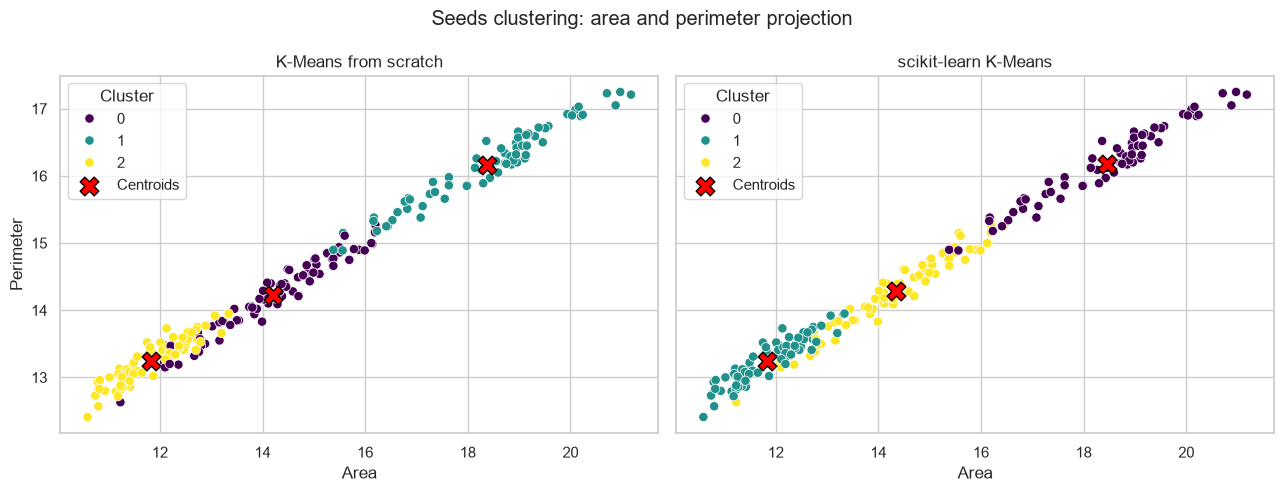

In [10]:
sklearn_table, sklearn_majority, sklearn_metrics = majority_class_evaluation(y, sklearn_labels)
print("True classes versus clusters (scikit-learn):")
display(sklearn_table)
print("Majority class assigned to each cluster:")
display(sklearn_majority.rename("Assigned class").to_frame())

classification_comparison = pd.DataFrame(
    [scratch_metrics, sklearn_metrics], index=["From scratch", "scikit-learn"],
)
print("Comparison after majority label assignment:")
display(classification_comparison.round(4))

# Show the first two measurements; clustering uses all seven standardized features
sklearn_centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, centroids, title in [
    (axes[0], scratch_labels, scratch_centroids_original, "K-Means from scratch"),
    (axes[1], sklearn_labels, sklearn_centroids_original, "scikit-learn K-Means"),
]:
    sns.scatterplot(
        data=df, x="Area", y="Perimeter", hue=labels,
        palette="viridis", s=45, ax=ax,
    )
    ax.scatter(
        centroids[:, 0], centroids[:, 1], marker="X",
        c="red", edgecolors="black", s=180, label="Centroids",
    )
    ax.set_title(title)
    ax.legend(title="Cluster")

fig.suptitle("Seeds clustering: area and perimeter projection")
plt.tight_layout()
plt.show()